### Geburtstagskuchen – Lösung Schritt für Schritt

*34. Bundeswettbewerb Informatik (2015/2016), 2. Runde, Aufgabe 1*

Linda hat für ihre Schwester einen Geburtstagskuchen in Herzform gebacken und Kerzen dafür gekauft. In einem Moment der
Unachtsamkeit hat ihr kleiner Bruder Luis die Kerzen bereits auf den Kuchen gesteckt:

*(Bild im Aufgabenblatt: ein Herz aus zwei Halbkreisen auf einem Dreieck, das nach unten spitz zuläuft. Luis hat zwölf Kerzen in
einer Reihe gesteckt, oben im rechten Bogen beginnend am rechten Rand entlang bis fast in die Spitze. Die linke Hälfte und die Mitte
sind leer.)*

Doch diese Verteilung der Kerzen gefällt Linda gar nicht; sie möchte die Kerzen möglichst gleichmäßig auf dem ganzen Kuchen
verteilen.

#### Aufgabe

1. Definiere ein formales Maß für die Gleichmäßigkeit einer Verteilung von Kerzen. Schreibe ein Programm, das die Tortenfläche
   sowie eine Liste von Koordinaten der einzelnen Kerzen einliest und den Wert deines Maßes ausgibt.
2. Schreibe ein Programm, das auf einer herzförmigen Tortenfläche eine gegebene Anzahl von Kerzen verteilt und ein Bild der
   Verteilung ausgibt. Sorge dafür, dass die Verteilung nach deinem Maß schön gleichmäßig und für Lindas Kuchen auf jeden Fall
   besser ist als die von Luis. Wende dein Programm auf verschiedene Kerzenzahlen an.

#### Beispieldaten

Zu dieser Aufgabe gibt es keine Beispieldaten. Wir haben das Herz und Luis' Kerzen deshalb aus dem Bild des Aufgabenblatts
ausgemessen und in `beispieldaten/kuchen_luis.txt` gespeichert (Maße in cm, mehr dazu in Schritt 1). In `eigene_testdaten/`
liegen weitere Kuchen: ein Quadrat mit verschiedenen Verteilungen, das Herz mit einem Kerzenhaufen in der Mitte, das Herz aus den
Lösungshinweisen und ein Stern.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Polygone:** Eine Fläche beschreiben wir durch die Liste ihrer Ecken. Runde Stücke (die Bögen des Herzens) ersetzen wir durch
  viele kurze Kanten.
- **Punkt im Polygon (Strahlmethode):** Ein Punkt liegt genau dann innen, wenn ein Strahl von ihm nach rechts den Rand ungerade oft
  schneidet. Das klappt auch bei nicht konvexen Flächen wie dem Herz.
- **Flächeninhalt eines Polygons** mit der *Gaußschen Trapezformel* (auch Schuhbandformel):
  `F = |x1·y2 − x2·y1 + x2·y3 − x3·y2 + … + xn·y1 − x1·yn| / 2`.
- **Abtasten mit einem Gitter:** Statt mit der Fläche selbst rechnen wir mit vielen Gitterpunkten im Abstand 0,5 cm, die im Kuchen
  liegen („Krümel“). Ein Mittelwert über alle Krümel ist dann ein Mittelwert über die Fläche.
- **Voronoi-Regionen:** Jeder Krümel gehört zu der Kerze, die ihm am nächsten ist. So zerfällt der Kuchen in Stücke, eines je Kerze.
- **Schwerpunkt** einer Menge von Punkten: Mittelwert der x- und der y-Koordinaten.
- **Lloyd-Algorithmus** (in der Datenanalyse als *k-Means* bekannt): Krümel der nächsten Kerze zuordnen, jede Kerze in den
  Schwerpunkt ihrer Krümel schieben, wiederholen, bis sich nichts mehr ändert.
- **Wabengitter:** In der unendlichen Ebene ist ein Gitter aus gleichseitigen Dreiecken (die Regionen sind dann Sechsecke wie bei
  Bienenwaben) die gleichmäßigste Verteilung. Es dient uns als Maßstab und als Startverteilung.

**Nützliche Funktionen und Bibliotheken**
- `math.hypot(dx, dy)` ist die Länge des Vektors `(dx, dy)`, also `math.sqrt(dx*dx + dy*dy)`.
- `random.Random(seed)` ist ein Zufallsgenerator mit fester Startzahl: Er liefert bei jedem Lauf dieselben Zufallszahlen, die
  Ergebnisse im Notebook lassen sich also wiederholen. `zufall.uniform(a, b)` liefert eine Kommazahl zwischen `a` und `b`.
- `matplotlib.pyplot`: `plot` für den Rand, `scatter` für Krümel und Kerzen, `set_aspect('equal')`, damit das Herz nicht verzerrt
  wird.
- Für Neugierige: `numpy` und `scipy.spatial.cKDTree` (sucht nächste Nachbarn sehr schnell) für Hunderte von Kerzen.

## Die Idee in Worten

**Teil 1: das Maß.** Stell dir vor, ein Gast zeigt auf eine zufällige Stelle des Kuchens. Wie weit ist es von dort bis zur
nächsten Kerze? Sind die Kerzen gleichmäßig verteilt, ist dieser Weg überall kurz. Stehen sie alle auf einer Seite, ist er auf der
anderen Seite lang. Unser Maß ist deshalb der **mittlere Abstand eines Kuchenpunkts zur nächsten Kerze**, kurz `d`.

`d` hängt noch von der Größe des Kuchens und von der Zahl der Kerzen ab: Mehr Kerzen machen die Wege immer kürzer. Wir teilen deshalb
durch den Wert, den ein perfektes Wabengitter mit derselben Kerzenzahl auf derselben Fläche hätte. Das Ergebnis heißt bei uns
**Gleichmäßigkeit G**:

- G = 1 heißt: so gut wie ein Wabengitter. Viel kleiner geht es nicht.
- G = 1,05 heißt: Ein Gast muss im Mittel 5 % weiter laufen als im Wabengitter.
- Je größer G, desto ungleichmäßiger.

Wir berechnen `d` nicht exakt, sondern mit den Krümeln: Für jeden Krümel suchen wir die nächste Kerze und mitteln die Abstände.
Das klappt für jede Fläche, die ein Polygon ist, nicht nur für das Herz.

**Teil 2: verteilen.** Wir verbessern eine Startverteilung schrittweise mit dem Lloyd-Algorithmus, wie die Lösungshinweise:
Jede Kerze wandert in den Schwerpunkt ihres Kuchenstücks. Dabei wird `d` nie größer (Begründung in Schritt 7). Als Start nehmen
wir ein Wabengitter (die „Basislösung“ der Hinweise) und einige Zufallsverteilungen und behalten das beste Ergebnis.

**Vergleich mit den Lösungshinweisen.** Die Hinweise berechnen die Kuchenstücke exakt (Voronoi-Diagramm über eine
Delaunay-Triangulierung und die konvexe Hülle in 3D). Das ist viel Geometrie mit vielen Sonderfällen. Unsere Krümel sind die
Alternative, die die Hinweise unter „Pixelgrafik“ erwähnen: etwas ungenauer, aber in wenigen Zeilen zu programmieren. Als Maß
nehmen die Hinweise den mittleren Abstand jeder Kerze zum Schwerpunkt ihres Stücks. Das rechnen wir in Schritt 9 auch aus und
zeigen, warum wir lieber `G` nehmen.

## Schritt 1: Den Kuchen einlesen

Das Dateiformat haben wir selbst festgelegt: In der ersten Zeile steht die Zahl der Ecken, dann je Zeile eine Ecke `x y`
(der Reihe nach um die Fläche herum). Danach kommt die Zahl der Kerzen und je Zeile eine Kerze `x y`. Alle Maße sind in cm.

In [ ]:
import math
import random

import matplotlib.pyplot as plt


def lies_kuchen(dateiname):
    with open(dateiname) as datei:
        zahlen = datei.read().split()          # alle Zahlen hintereinander, egal wie die Zeilen aussehen
    pos = 0
    ecken = []
    anzahl = int(zahlen[pos])
    pos += 1
    for i in range(anzahl):
        ecken.append((float(zahlen[pos]), float(zahlen[pos + 1])))
        pos += 2
    kerzen = []
    anzahl = int(zahlen[pos])
    pos += 1
    for i in range(anzahl):
        kerzen.append((float(zahlen[pos]), float(zahlen[pos + 1])))
        pos += 2
    return ecken, kerzen


herz, luis = lies_kuchen('beispieldaten/kuchen_luis.txt')
print(len(herz), 'Ecken, die ersten fünf:', herz[:5])
print(len(luis), 'Kerzen von Luis:', luis)

92 Ecken, die ersten fünf: [(0.0, 0.0), (0.04, 0.87), (0.15, 1.74), (0.34, 2.59), (0.6, 3.42)]
12 Kerzen von Luis: [(11.0, 7.4), (14.4, 6.3), (16.3, 3.3), (16.7, 0.0), (15.9, -2.9), (13.9, -5.4), (11.7, -8.0), (9.6, -10.7), (7.3, -12.9), (4.8, -15.8), (2.6, -18.5), (0.3, -21.3)]


**Wie wir das Herz gebaut haben.** Im Aufgabenblatt besteht das Herz aus zwei Kreisen mit gleichem Radius, die sich in der Mitte
berühren, und zwei Geraden, die die Kreise berühren und sich unten in der Spitze treffen. Ausgemessen (nach einem Bild des
Aufgabenblatts mit 300 dpi) ist die Spitze 2,67 Radien unter den Kreismittelpunkten. Wir nehmen den Radius 10 cm, dann ist das Herz
40 cm breit. Der Ursprung `(0, 0)` ist die Einbuchtung oben in der Mitte. Die Bögen ersetzen wir durch Ecken im Abstand von 5°.
Die Funktion `herz_aufgabe` rechnet die Ecken aus; sie stimmen mit der Datei überein. Luis' Kerzen haben wir genauso aus dem Bild
ausgemessen.

In [ ]:
def herz_aufgabe(R=10, tief=26.7, schritt=5):
    """Herz aus zwei Kreisen (Radius R, Mittelpunkte (-R, 0) und (R, 0)) und der Spitze (0, -tief)."""
    # Berührpunkt der Geraden von der Spitze an den rechten Kreis: Winkel vom Mittelpunkt (R, 0) aus
    abstand = math.hypot(R, tief)                       # Spitze bis Mittelpunkt
    beruehr = math.atan2(-tief, -R) + math.acos(R / abstand)
    ecken = []
    w = 180                                             # rechter Bogen: von der Einbuchtung (180°) im Uhrzeigersinn
    while w > math.degrees(beruehr):
        ecken.append((R + R * math.cos(math.radians(w)), R * math.sin(math.radians(w))))
        w -= schritt
    ecken.append((R + R * math.cos(beruehr), R * math.sin(beruehr)))
    rechts = ecken[1:]                                  # ohne die Einbuchtung
    ecken.append((0, -tief))                            # die Spitze
    for x, y in reversed(rechts):                       # linke Hälfte gespiegelt, rückwärts
        ecken.append((-x, y))
    return [(round(x, 2) + 0.0, round(y, 2) + 0.0) for x, y in ecken]    # + 0.0 macht aus -0.0 eine 0.0


print(herz_aufgabe() == herz)
print('Berührpunkt rechts:', herz[45], ' Spitze:', herz[46])

True
Berührpunkt rechts: (17.54, -6.57)  Spitze: (0.0, -26.7)


Zum Zeichnen schreiben wir eine Funktion, die wir immer wieder brauchen: Sie zeichnet den Rand, auf Wunsch die Krümel (farbig nach
ihrer Kerze, das gibt die Kuchenstücke) und die Kerzen als rote Punkte.

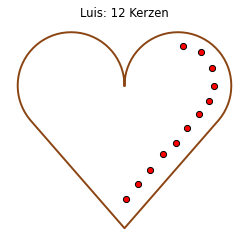

In [ ]:
FARBEN = ['#aec7e8', '#ffbb78', '#98df8a', '#ff9896', '#c5b0d5', '#c49c94', '#f7b6d2', '#dbdb8d', '#9edae5',
          '#c7c7c7', '#fdd0a2', '#bcbddc', '#a1d99b']


def zeichne(achse, ecken, kerzen, punkte=None, zu=None, titel=''):
    if punkte is not None and zu is not None:          # Kuchenstücke: jeder Krümel in der Farbe seiner Kerze
        farben = [FARBEN[k % len(FARBEN)] for k in zu]
        achse.scatter([p[0] for p in punkte], [p[1] for p in punkte], c=farben, s=16, marker='s', linewidths=0)
    rand = ecken + [ecken[0]]                          # zurück zur ersten Ecke
    achse.plot([p[0] for p in rand], [p[1] for p in rand], color='saddlebrown', linewidth=2)
    if kerzen:
        achse.scatter([k[0] for k in kerzen], [k[1] for k in kerzen], color='red', edgecolors='black', s=40, zorder=3)
    achse.set_aspect('equal')
    achse.set_title(titel)
    achse.axis('off')


fig, achse = plt.subplots(figsize=(5, 4))
zeichne(achse, herz, luis, titel='Luis: 12 Kerzen')
plt.show()

## Schritt 2: Fläche, Punkt im Polygon und Krümel

`innen` ist die Strahlmethode: Wir gehen alle Kanten durch. Eine Kante zählt, wenn sie die waagerechte Linie durch den Punkt kreuzt
(ein Ende darüber, eines nicht) und der Schnittpunkt rechts vom Punkt liegt. Bei einer ungeraden Zahl solcher Kanten liegt der
Punkt innen. `flaeche` ist die Gaußsche Trapezformel. `kuchenpunkte` legt ein Gitter mit Abstand `h` über das umgebende Rechteck
und behält die Punkte im Kuchen. Jeder Krümel steht für ein Quadrat der Fläche `h²`, also sollte `Anzahl · h²` ungefähr die Fläche sein.

In [ ]:
def innen(x, y, ecken):
    drin = False
    for i in range(len(ecken)):
        x1, y1 = ecken[i]
        x2, y2 = ecken[(i + 1) % len(ecken)]           # nächste Ecke, nach der letzten wieder die erste
        if (y1 > y) != (y2 > y):                       # Kante kreuzt die Waagerechte durch den Punkt
            xs = x1 + (y - y1) * (x2 - x1) / (y2 - y1)  # dort liegt der Schnittpunkt
            if xs > x:                                 # rechts vom Punkt: der Strahl trifft die Kante
                drin = not drin
    return drin


def flaeche(ecken):
    summe = 0
    for i in range(len(ecken)):
        x1, y1 = ecken[i]
        x2, y2 = ecken[(i + 1) % len(ecken)]
        summe += x1 * y2 - x2 * y1
    return abs(summe) / 2


def kuchenpunkte(ecken, h=0.5):
    xmin = min(p[0] for p in ecken)
    xmax = max(p[0] for p in ecken)
    ymin = min(p[1] for p in ecken)
    ymax = max(p[1] for p in ecken)
    punkte = []
    zeilen = int((ymax - ymin) / h)
    spalten = int((xmax - xmin) / h)
    for j in range(zeilen + 1):
        y = ymin + h / 2 + j * h                       # Mitte der Gitterzelle
        for i in range(spalten + 1):
            x = xmin + h / 2 + i * h
            if innen(x, y, ecken):
                punkte.append((x, y))
    return punkte


F_herz = flaeche(herz)
krumen = kuchenpunkte(herz)
print('Fläche des Herzens: %.1f cm²' % F_herz)
print('Krümel:', len(krumen), ' Anzahl · h² = %.2f cm²' % (len(krumen) * 0.25))
print('Ist die Mitte (0, -10) innen?', innen(0, -10, herz), ' Ist (0, 5) innen?', innen(0, 5, herz))

Fläche des Herzens: 919.4 cm²
Krümel: 3674  Anzahl · h² = 918.50 cm²
Ist die Mitte (0, -10) innen? True  Ist (0, 5) innen? False


## Schritt 3: Das Maß

`naechste_kerze` sucht für jeden Krümel die nächste Kerze und liefert zwei Listen: die Nummer dieser Kerze (`zu`) und den
Abstand. Der Mittelwert der Abstände ist `d`.

**Der Maßstab Wabengitter.** Teilt man die Fläche `F` in `n` gleich große regelmäßige Sechsecke mit einer Kerze in jeder Mitte, dann
hat jedes Sechseck die Fläche `A = F / n`. Der mittlere Abstand eines Punkts im Sechseck von seiner Mitte ist `c · √A` mit einer
festen Zahl `c`. Diese Zahl rechnen wir mit unseren eigenen Werkzeugen aus: ein Sechseck mit Fläche 1, ganz feine Krümel und eine
einzige Kerze in der Mitte. Zum Vergleich auch für ein Quadrat und einen Kreis, jeweils mit Fläche 1.

In [ ]:
def naechste_kerze(punkte, kerzen):
    zu = []
    abstand = []
    for px, py in punkte:
        beste = 0
        beste_d2 = math.inf
        for k in range(len(kerzen)):
            kx, ky = kerzen[k]
            d2 = (px - kx) ** 2 + (py - ky) ** 2        # Quadrat des Abstands genügt zum Vergleichen
            if d2 < beste_d2:
                beste_d2 = d2
                beste = k
        zu.append(beste)
        abstand.append(math.sqrt(beste_d2))
    return zu, abstand


def regelmaessig(ecken_zahl, flaeche_soll):
    """Regelmäßiges Vieleck um (0, 0) mit der gewünschten Fläche."""
    r = 1.0
    ecken = [(r * math.cos(2 * math.pi * i / ecken_zahl), r * math.sin(2 * math.pi * i / ecken_zahl))
             for i in range(ecken_zahl)]
    faktor = math.sqrt(flaeche_soll / flaeche(ecken))
    return [(x * faktor, y * faktor) for x, y in ecken]


for name, ecken_zahl in [('Quadrat', 4), ('Sechseck', 6), ('Kreis (360 Ecken)', 360)]:
    form = regelmaessig(ecken_zahl, 1)
    pkte = kuchenpunkte(form, 0.004)
    zu, abstand = naechste_kerze(pkte, [(0, 0)])
    print('%-18s %6d Krümel, mittlerer Abstand zur Mitte: %.4f' % (name, len(pkte), sum(abstand) / len(abstand)))

Quadrat             62481 Krümel, mittlerer Abstand zur Mitte: 0.3825
Sechseck            62557 Krümel, mittlerer Abstand zur Mitte: 0.3774
Kreis (360 Ecken)   62498 Krümel, mittlerer Abstand zur Mitte: 0.3761


Genau gerechnet (mit einem Integral) ist `c = 0,3772` für das Sechseck. Der Kreis wäre noch etwas besser, aber mit Kreisen kann man
die Fläche nicht lückenlos auslegen; das Quadrat ist schlechter. Damit ist unser Maß

```
G = d / (0,3772 · √(F / n))
```

`gleichmaessigkeit` rechnet `d` und `G` aus. `bewerte` ist das Programm für Teil 1: Kuchen einlesen, Krümel bilden, Maß ausgeben.

In [ ]:
WABE = 0.3772


def gleichmaessigkeit(ecken, punkte, kerzen):
    zu, abstand = naechste_kerze(punkte, kerzen)
    d = sum(abstand) / len(abstand)
    G = d / (WABE * math.sqrt(flaeche(ecken) / len(kerzen)))
    return d, G


def bewerte(dateiname):
    ecken, kerzen = lies_kuchen(dateiname)
    punkte = kuchenpunkte(ecken)
    d, G = gleichmaessigkeit(ecken, punkte, kerzen)
    print('%-34s Fläche %6.1f cm², %2d Kerzen, d = %5.2f cm, G = %.3f' % (dateiname, flaeche(ecken), len(kerzen), d, G))


bewerte('beispieldaten/kuchen_luis.txt')

beispieldaten/kuchen_luis.txt      Fläche  919.4 cm², 12 Kerzen, d = 10.27 cm, G = 3.110


Bei Luis' Kerzen läuft ein Gast im Mittel über 10 cm bis zur nächsten Kerze, gut dreimal so weit wie im Wabengitter.

**Wie genau sind die Krümel?** Wir rechnen das Maß für Luis mit verschiedenen Gitterabständen aus. Von 0,5 cm zu 0,25 cm ändert sich
`G` nur noch um weniger als 0,001; feiner lohnt sich nicht, die Rechenzeit wächst mit der Zahl der Krümel.

In [ ]:
for h in [2, 1, 0.5, 0.25]:
    pkte = kuchenpunkte(herz, h)
    d, G = gleichmaessigkeit(herz, pkte, luis)
    print('h = %4.2f cm: %5d Krümel, d = %.3f cm, G = %.4f' % (h, len(pkte), d, G))

h = 2.00 cm:   232 Krümel, d = 10.355 cm, G = 3.1364
h = 1.00 cm:   922 Krümel, d = 10.281 cm, G = 3.1137
h = 0.50 cm:  3674 Krümel, d = 10.268 cm, G = 3.1098
h = 0.25 cm: 14722 Krümel, d = 10.270 cm, G = 3.1106


## Schritt 4: Passt das Maß zur Anschauung?

Wir bewerten alle Testkuchen und rechnen zum Vergleich ein anderes naheliegendes Maß aus: den **kleinsten Abstand zweier Kerzen**
(je größer, desto besser?). Die Quadrate haben die Seitenlänge 30 cm und je vier Kerzen:

- `quadrat_mitte.txt`: je eine Kerze in der Mitte jedes Viertels,
- `quadrat_ecken.txt`: je eine Kerze in jeder Ecke,
- `quadrat_schief.txt`: vier Kerzen, grob verteilt,
- `quadrat_haufen.txt`: alle vier dicht beieinander in einer Ecke,
- `herz_haufen.txt`: Luis' Reihe, verkleinert auf ein Drittel, in der Mitte des Herzens.

eigene_testdaten/quadrat_mitte.txt   G = 1.014   kleinster Abstand  15.0 cm
eigene_testdaten/quadrat_ecken.txt   G = 2.028   kleinster Abstand  30.0 cm
eigene_testdaten/quadrat_schief.txt  G = 1.151   kleinster Abstand  12.2 cm
eigene_testdaten/quadrat_haufen.txt  G = 2.776   kleinster Abstand   3.0 cm
beispieldaten/kuchen_luis.txt        G = 3.110   kleinster Abstand   3.0 cm
eigene_testdaten/herz_haufen.txt     G = 2.916   kleinster Abstand   0.9 cm


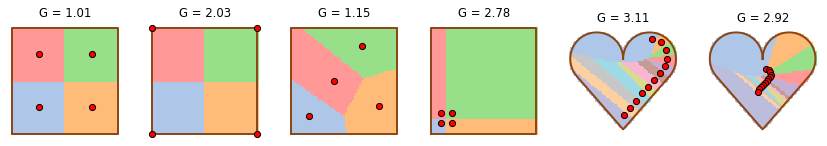

In [ ]:
def kleinster_abstand(kerzen):
    kleinster = math.inf
    for i in range(len(kerzen)):
        for j in range(i + 1, len(kerzen)):
            kleinster = min(kleinster, math.hypot(kerzen[i][0] - kerzen[j][0], kerzen[i][1] - kerzen[j][1]))
    return kleinster


TESTKUCHEN = ['eigene_testdaten/quadrat_mitte.txt', 'eigene_testdaten/quadrat_ecken.txt',
              'eigene_testdaten/quadrat_schief.txt', 'eigene_testdaten/quadrat_haufen.txt',
              'beispieldaten/kuchen_luis.txt', 'eigene_testdaten/herz_haufen.txt']
fig, achsen = plt.subplots(1, 6, figsize=(15, 3))
for i in range(len(TESTKUCHEN)):
    ecken, kerzen = lies_kuchen(TESTKUCHEN[i])
    pkte = kuchenpunkte(ecken)
    d, G = gleichmaessigkeit(ecken, pkte, kerzen)
    zu, abstand = naechste_kerze(pkte, kerzen)
    print('%-36s G = %.3f   kleinster Abstand %5.1f cm' % (TESTKUCHEN[i], G, kleinster_abstand(kerzen)))
    zeichne(achsen[i], ecken, kerzen, pkte, zu, 'G = %.2f' % G)
plt.show()

Die Reihenfolge nach `G` passt zur Anschauung: Die Viertelmitten sind am besten (G = 1,014, so gut wie Quadrate eben sind, siehe
Schritt 3: 0,3826 / 0,3772), die grobe Verteilung ist mittelmäßig, Haufen sind schlecht. Kerzen **in den Ecken** werden mit G = 2,03
klar bestraft: Die Mitte des Kuchens ist weit von jeder Kerze entfernt, und die Hälfte jedes Kuchenstücks läge außerhalb.

Der **kleinste Abstand** dagegen hält die Ecken für die beste Verteilung (30 cm), denn weiter auseinander geht es im Quadrat nicht.
Das ist genau das Problem, das die Lösungshinweise beschreiben: Wer nur den Abstand der Kerzen untereinander betrachtet, treibt die
Kerzen an den Rand. Außerdem sieht dieses Maß nur das eine schlechteste Paar. Bei `G` zählt dagegen jeder Punkt des Kuchens, und der
Rand ist automatisch berücksichtigt, weil auch die Krümel am Rand eine Kerze in der Nähe brauchen.

Damit ist Teil 1 gelöst: `bewerte` liest eine beliebige Fläche (jedes Polygon, auch nicht konvex) und Kerzen ein und gibt `G` aus.

## Schritt 5: Version 0 – Kerzen zufällig verteilen

Als Vergleich verteilen wir die Kerzen zufällig: Wir würfeln Punkte im umgebenden Rechteck und behalten die, die im Kuchen liegen.

In [ ]:
def zufaellig(ecken, n, seed):
    zufall = random.Random(seed)
    xmin = min(p[0] for p in ecken)
    xmax = max(p[0] for p in ecken)
    ymin = min(p[1] for p in ecken)
    ymax = max(p[1] for p in ecken)
    kerzen = []
    while len(kerzen) < n:
        x = zufall.uniform(xmin, xmax)
        y = zufall.uniform(ymin, ymax)
        if innen(x, y, ecken):
            kerzen.append((x, y))
    return kerzen


for seed in range(5):
    k = zufaellig(herz, 12, seed)
    print('Zufall %d: G = %.3f' % (seed, gleichmaessigkeit(herz, krumen, k)[1]))

Zufall 0: G = 1.462
Zufall 1: G = 1.354
Zufall 2: G = 1.625
Zufall 3: G = 1.467
Zufall 4: G = 1.501


Zufällig verteilte Kerzen sind schon viel besser als Luis' Reihe, aber noch weit vom Wabengitter entfernt: Zufall bildet Lücken
und Haufen.

## Schritt 6: Version 1 – ein Wabengitter auflegen

Das ist die Basislösung der Lösungshinweise. Ein Wabengitter mit Abstand `s` hat Reihen im Abstand `s · √3 / 2`; jede zweite Reihe
ist um `s / 2` verschoben. Jede Kerze beansprucht dann die Fläche `s² · √3 / 2`. Für `n` Kerzen auf der Fläche `F` schätzen wir also
`s ≈ √(2F / (√3 · n))`.

Am Rand passt das Gitter aber nicht genau: Mal liegen ein paar Punkte mehr, mal ein paar weniger im Herz. Wir probieren deshalb
Abstände von 85 % bis 115 % der Schätzung und je 9 Verschiebungen des Gitters (um 0, ⅓ oder ⅔ von `s` in x- und in y-Richtung) und
behalten unter allen Gittern mit **genau** `n` Punkten im Kuchen das mit dem kleinsten `G`.

12 Kerzen: 279 Gitter probiert, 46 mit genau 12 Punkten, bestes G = 1.074


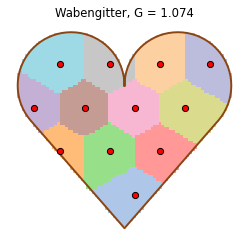

In [ ]:
def wabengitter(ecken, s, dx, dy):
    """Alle Punkte eines Wabengitters mit Abstand s im Kuchen; dx, dy verschieben das Gitter (in Teilen von s)."""
    xmin = min(p[0] for p in ecken)
    xmax = max(p[0] for p in ecken)
    ymin = min(p[1] for p in ecken)
    ymax = max(p[1] for p in ecken)
    reihenabstand = s * math.sqrt(3) / 2
    punkte = []
    reihe = 0
    y = ymin + dy * s
    while y < ymax:
        x = xmin + dx * s
        if reihe % 2 == 1:
            x += s / 2                                  # jede zweite Reihe versetzt
        while x < xmax:
            if innen(x, y, ecken):
                punkte.append((x, y))
            x += s
        y += reihenabstand
        reihe += 1
    return punkte


def bestes_wabengitter(ecken, punkte, n):
    schaetzung = math.sqrt(2 * flaeche(ecken) / (math.sqrt(3) * n))
    beste, bestes_G, probiert, passend = None, math.inf, 0, 0
    for i in range(31):
        s = schaetzung * (0.85 + 0.01 * i)
        for dx in [0, 1 / 3, 2 / 3]:
            for dy in [0, 1 / 3, 2 / 3]:
                gitter = wabengitter(ecken, s, dx, dy)
                probiert += 1
                if len(gitter) == n:                     # nur Gitter mit genau n Kerzen
                    passend += 1
                    G = gleichmaessigkeit(ecken, punkte, gitter)[1]
                    if G < bestes_G:
                        beste, bestes_G = gitter, G
    return beste, bestes_G, probiert, passend


waben12, G_waben12, probiert, passend = bestes_wabengitter(herz, krumen, 12)
print('12 Kerzen: %d Gitter probiert, %d mit genau 12 Punkten, bestes G = %.3f' % (probiert, passend, G_waben12))
fig, achse = plt.subplots(figsize=(5, 4))
zeichne(achse, herz, waben12, krumen, naechste_kerze(krumen, waben12)[0], 'Wabengitter, G = %.3f' % G_waben12)
plt.show()

Das Wabengitter ist schon sehr gut. Am Rand passen die Waben aber nicht: Dort sind die Stücke abgeschnitten oder zu groß. Bei
manchen Kerzenzahlen findet man vielleicht gar kein Gitter mit genau `n` Punkten im Herz; das sagen auch die Lösungshinweise
(„Gute Verteilungen lassen sich zwar für einige, aber nicht für alle Kerzenzahlen finden“). Dann ergänzen die Hinweise Kerzen in den
Mitten der Dreiecke. Wir verbessern das Gitter stattdessen gleich mit dem Lloyd-Algorithmus.

## Schritt 7: Version 2 – der Lloyd-Algorithmus

Ein Schritt besteht aus zwei Teilen:

1. Jeder Krümel gehört zur nächsten Kerze (`naechste_kerze`). So entstehen die Kuchenstücke.
2. Jede Kerze wandert in den **Schwerpunkt** ihres Stücks.

Das wiederholen wir, bis sich die Zuordnung der Krümel nicht mehr ändert. Dann bleiben auch die Schwerpunkte gleich, und die
Kerzen bewegen sich nicht mehr.

**Warum wird es nie schlechter?** Teil 2 verschiebt jede Kerze an die Stelle, von der aus die Krümel ihres Stücks im Mittel am
nächsten sind (genau genommen ist der Schwerpunkt die beste Stelle für die *Quadrate* der Abstände; das reicht, damit der
Algorithmus anhält). Teil 1 gibt jedem Krümel die nächste Kerze, auch das macht keinen Weg länger. Die Summe der Quadrate kann also
nur kleiner werden. Da es nur endlich viele Zuordnungen gibt, hält der Algorithmus irgendwann an. `d` und `G` sinken dabei meistens
mit, wie die Ausgabe zeigt.

Zum Mitzählen gibt `lloyd` die Zahl der Schritte zurück und merkt sich `G` nach jedem Schritt.

Zufallsstart, 12 Kerzen: 54 Schritte
  nach   0 Schritten: G = 1.4615
  nach   1 Schritten: G = 1.1522
  nach   2 Schritten: G = 1.1023
  nach   5 Schritten: G = 1.0551
  nach  10 Schritten: G = 1.0323
  nach  20 Schritten: G = 1.0264
  nach  54 Schritten: G = 1.0255


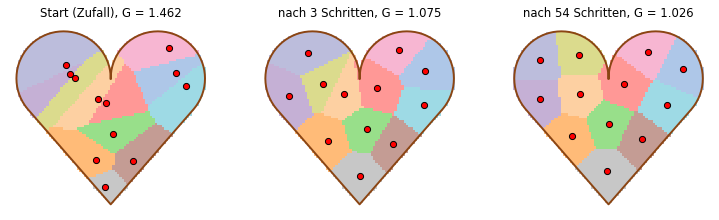

In [ ]:
def schwerpunkte(punkte, zu, kerzen):
    sx = [0.0] * len(kerzen)
    sy = [0.0] * len(kerzen)
    anzahl = [0] * len(kerzen)
    for i in range(len(punkte)):
        k = zu[i]
        sx[k] += punkte[i][0]
        sy[k] += punkte[i][1]
        anzahl[k] += 1
    neu = []
    for k in range(len(kerzen)):
        if anzahl[k] > 0:
            neu.append((sx[k] / anzahl[k], sy[k] / anzahl[k]))
        else:
            neu.append(kerzen[k])                       # Kerze ohne Krümel bleibt stehen
    return neu


def lloyd(ecken, punkte, kerzen, max_schritte=1000):
    nenner = WABE * math.sqrt(flaeche(ecken) / len(kerzen))
    verlauf = []                                        # G vor jedem Schritt
    alt = None
    for schritt in range(max_schritte):
        zu, abstand = naechste_kerze(punkte, kerzen)
        verlauf.append(sum(abstand) / len(abstand) / nenner)
        if zu == alt:                                   # nichts hat sich geändert: fertig
            return kerzen, schritt, verlauf
        alt = zu
        kerzen = schwerpunkte(punkte, zu, kerzen)
    return kerzen, max_schritte, verlauf


start12 = zufaellig(herz, 12, 0)
linda12, schritte, verlauf = lloyd(herz, krumen, start12)
print('Zufallsstart, 12 Kerzen:', schritte, 'Schritte')
for s in [0, 1, 2, 5, 10, 20, schritte]:
    print('  nach %3d Schritten: G = %.4f' % (s, verlauf[s]))

fig, achsen = plt.subplots(1, 3, figsize=(13, 4))
zwischen, _, _ = lloyd(herz, krumen, start12, max_schritte=3)
for achse, k, titel in [(achsen[0], start12, 'Start (Zufall)'), (achsen[1], zwischen, 'nach 3 Schritten'),
                        (achsen[2], linda12, 'nach %d Schritten' % schritte)]:
    zeichne(achse, herz, k, krumen, naechste_kerze(krumen, k)[0], titel + ', G = %.3f' % gleichmaessigkeit(herz, krumen, k)[1])
plt.show()

Schon nach wenigen Schritten sind die Lücken des Zufallsstarts gefüllt; danach rücken die Kerzen nur noch wenig. Am Ende sind die
Stücke ungefähr gleich groß und rundlich, und die Kerzen am Rand halten etwas Abstand zum Rand. Bei vielen Kerzen werden die Stücke
im Inneren zu Sechsecken (Schritt 10).

Lloyd findet aber nur ein **lokales** Optimum: Von einem anderen Start aus kommt man oft woanders an. Wir vergleichen fünf
Zufallsstarts und das Wabengitter als Start.

In [ ]:
for seed in range(5):
    k, schritte, verlauf = lloyd(herz, krumen, zufaellig(herz, 12, seed))
    print('Zufallsstart %d: %3d Schritte, G = %.4f' % (seed, schritte, verlauf[-1]))
k, schritte, verlauf = lloyd(herz, krumen, waben12)
print('Wabengitter:    %3d Schritte, G = %.4f (vorher %.4f)' % (schritte, verlauf[-1], verlauf[0]))

Zufallsstart 0:  54 Schritte, G = 1.0255
Zufallsstart 1:  51 Schritte, G = 1.0261
Zufallsstart 2:  86 Schritte, G = 1.0234
Zufallsstart 3:  43 Schritte, G = 1.0235
Zufallsstart 4:  31 Schritte, G = 1.0349
Wabengitter:     35 Schritte, G = 1.0288 (vorher 1.0735)


## Schritt 8: Version 3 – mehrere Starts, das Beste behalten

`verteile` ist das Programm für Teil 2: Es startet Lloyd vom besten Wabengitter (falls es eines gibt) und von einigen
Zufallsverteilungen und behält das Ergebnis mit dem kleinsten `G`.

Linda, 12 Kerzen: G = 1.0234 (Start: Zufall 2, 86 Schritte)
Luis,  12 Kerzen: G = 3.1098


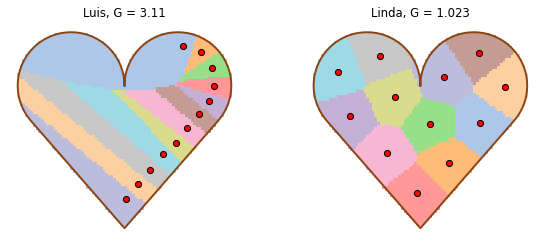

In [ ]:
def verteile(ecken, punkte, n, zufallsstarts=3):
    starts = []
    gitter, G_gitter, probiert, passend = bestes_wabengitter(ecken, punkte, n)
    if gitter is not None:
        starts.append(('Wabengitter', gitter))
    for seed in range(zufallsstarts):
        starts.append(('Zufall %d' % seed, zufaellig(ecken, n, seed)))
    bestes = None
    for name, start in starts:
        kerzen, schritte, verlauf = lloyd(ecken, punkte, start)
        if bestes is None or verlauf[-1] < bestes['G']:
            bestes = {'kerzen': kerzen, 'G': verlauf[-1], 'start': name, 'schritte': schritte, 'G_gitter': G_gitter}
    return bestes


linda = verteile(herz, krumen, 12)
print('Linda, 12 Kerzen: G = %.4f (Start: %s, %d Schritte)' % (linda['G'], linda['start'], linda['schritte']))
print('Luis,  12 Kerzen: G = %.4f' % gleichmaessigkeit(herz, krumen, luis)[1])

fig, achsen = plt.subplots(1, 2, figsize=(10, 4))
zeichne(achsen[0], herz, luis, krumen, naechste_kerze(krumen, luis)[0],
        'Luis, G = %.2f' % gleichmaessigkeit(herz, krumen, luis)[1])
zeichne(achsen[1], herz, linda['kerzen'], krumen, naechste_kerze(krumen, linda['kerzen'])[0], 'Linda, G = %.3f' % linda['G'])
plt.show()

Lindas Verteilung ist nach unserem Maß dreimal so gut wie die von Luis, und man sieht es auch: Luis' Kuchenstücke links sind riesig.

## Schritt 9: Das Maß der Lösungshinweise

Die Lösungshinweise messen den **mittleren Abstand jeder Kerze vom Schwerpunkt ihres Kuchenstücks** (wir nennen ihn `S`). Steht jede
Kerze im Schwerpunkt ihres Stücks, ist `S = 0`; genau dort hält Lloyd an. Mit unseren Funktionen ist `S` schnell ausgerechnet:

In [ ]:
def mass_hinweise(punkte, kerzen):
    zu, abstand = naechste_kerze(punkte, kerzen)
    mitte = schwerpunkte(punkte, zu, kerzen)
    summe = 0
    for k in range(len(kerzen)):
        summe += math.hypot(kerzen[k][0] - mitte[k][0], kerzen[k][1] - mitte[k][1])
    return summe / len(kerzen)


print('Luis:  S = %.3f cm' % mass_hinweise(krumen, luis))
print('Linda: S = %.3f cm' % mass_hinweise(krumen, linda['kerzen']))

Luis:  S = 5.742 cm
Linda: S = 0.000 cm


Für Luis ist `S` groß, für Lindas Verteilung 0 (in den Hinweisen „etwa 0.00001“, weil dort mit Kommazahlen exakt gerechnet und nach
500 Schritten abgebrochen wird). Allerdings ist **jedes** Ergebnis des Lloyd-Algorithmus ein Fall mit `S = 0`, auch ein schlechtes
lokales Optimum. Ein kleines Beispiel mit zwei Kerzen: Wir starten Lloyd mit zwei Kerzen übereinander, nebeneinander und schräg.

Start [(0, 2), (0, -15)]: Kerzen bei (0.0, 1.1) und (0.0, -13.0), S = 0.000, G = 1.2060
Start [(-8, -3), (8, -3)]: Kerzen bei (-8.3, -4.5) und (8.3, -4.5), S = 0.000, G = 1.1000
Start [(-8, -6), (9, -3)]: Kerzen bei (-7.3, -5.8) und (9.2, -3.0), S = 0.000, G = 1.0995


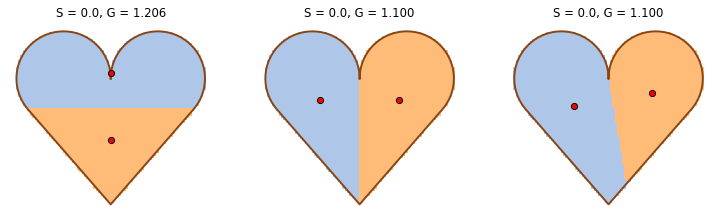

In [ ]:
fig, achsen = plt.subplots(1, 3, figsize=(13, 4))
starts2 = [[(0, 2), (0, -15)], [(-8, -3), (8, -3)], [(-8, -6), (9, -3)]]
for i in range(3):
    k, schritte, verlauf = lloyd(herz, krumen, starts2[i])
    S = mass_hinweise(krumen, k)
    print('Start %s: Kerzen bei (%.1f, %.1f) und (%.1f, %.1f), S = %.3f, G = %.4f' % (
        starts2[i], k[0][0], k[0][1], k[1][0], k[1][1], S, verlauf[-1]))
    zeichne(achsen[i], herz, k, krumen, naechste_kerze(krumen, k)[0], 'S = %.1f, G = %.3f' % (S, verlauf[-1]))
plt.show()

Alle drei Verteilungen haben `S = 0`, sind also für die Hinweise gleich gut. Zwei Kerzen übereinander lassen aber die äußeren Teile
der beiden Bögen links und rechts weit weg von jeder Kerze; `G` sieht das und bewertet diese Verteilung deutlich schlechter (1,206).
Nebeneinander und schräg sind fast gleich gut (1,1000 und 1,0995). Außerdem hat `S` die Einheit cm und
hängt von der Größe des Kuchens ab; `G` ist eine reine Zahl, die man auch zwischen verschiedenen Kerzenzahlen vergleichen kann.
Deshalb bleiben wir bei `G`. Lloyd ist trotzdem das richtige Verfahren: Er macht `G` (fast immer) kleiner, und mit mehreren Starts
finden wir die besseren Optima.

## Schritt 10: Alle Beispiele

Wir verteilen verschiedene Kerzenzahlen auf das Herz der Aufgabe, jeweils mit drei Zufallsstarts und dem Wabengitter. In der Tabelle
steht `G` für das beste Wabengitter allein (Version 1) und nach Lloyd (Version 3) sowie der Start, von dem das beste Ergebnis kam.

In [ ]:
ergebnisse = {}


def tabelle(zahlen, zufallsstarts=3):
    for n in zahlen:
        e = verteile(herz, krumen, n, zufallsstarts)
        ergebnisse[n] = e
        gitter = '  -  ' if e['G_gitter'] == math.inf else '%.3f' % e['G_gitter']
        print('%3d Kerzen: Wabengitter G = %s, Lloyd G = %.3f (Start: %s, %d Schritte)' % (
            n, gitter, e['G'], e['start'], e['schritte']))


tabelle([1, 2, 3, 4, 5, 6, 8, 10, 12])

  1 Kerzen: Wabengitter G = 1.049, Lloyd G = 1.045 (Start: Wabengitter, 1 Schritte)
  2 Kerzen: Wabengitter G = 1.196, Lloyd G = 1.100 (Start: Wabengitter, 18 Schritte)
  3 Kerzen: Wabengitter G = 1.037, Lloyd G = 1.007 (Start: Wabengitter, 8 Schritte)
  4 Kerzen: Wabengitter G = 1.125, Lloyd G = 1.046 (Start: Zufall 1, 27 Schritte)
  5 Kerzen: Wabengitter G = 1.115, Lloyd G = 1.050 (Start: Zufall 2, 30 Schritte)
  6 Kerzen: Wabengitter G = 1.052, Lloyd G = 1.031 (Start: Zufall 1, 51 Schritte)
  8 Kerzen: Wabengitter G = 1.102, Lloyd G = 1.026 (Start: Zufall 0, 70 Schritte)
 10 Kerzen: Wabengitter G = 1.052, Lloyd G = 1.022 (Start: Wabengitter, 25 Schritte)
 12 Kerzen: Wabengitter G = 1.074, Lloyd G = 1.023 (Start: Zufall 2, 86 Schritte)


In [ ]:
tabelle([24, 50])

 24 Kerzen: Wabengitter G = 1.045, Lloyd G = 1.015 (Start: Wabengitter, 28 Schritte)
 50 Kerzen: Wabengitter G = 1.033, Lloyd G = 1.011 (Start: Wabengitter, 15 Schritte)


100 Kerzen: Wabengitter G = 1.030, Lloyd G = 1.009 (Start: Wabengitter, 12 Schritte)


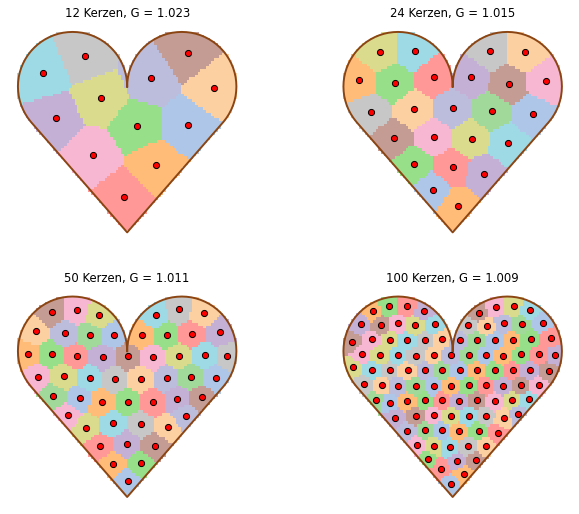

In [ ]:
tabelle([100], zufallsstarts=1)

fig, achsen = plt.subplots(2, 2, figsize=(11, 9))
for achse, n in zip([achsen[0][0], achsen[0][1], achsen[1][0], achsen[1][1]], [12, 24, 50, 100]):
    k = ergebnisse[n]['kerzen']
    zeichne(achse, herz, k, krumen, naechste_kerze(krumen, k)[0], '%d Kerzen, G = %.3f' % (n, ergebnisse[n]['G']))
plt.show()

**Was die Beispiele zeigen.**
- Ab 3 Kerzen liegt `G` nach Lloyd höchstens etwa 5 % über 1, also fast so gut wie ein Wabengitter in der unendlichen Ebene; je mehr
  Kerzen, desto näher an 1 (100 Kerzen: 1,009). Für 12 Kerzen ist Lindas Kuchen dreimal so gleichmäßig wie der von Luis.
- Bei sehr wenigen Kerzen passt das Herz nicht zu Waben: Mit 2 Kerzen sind die Stücke zwei halbe Herzen, `G` liegt 10 % über 1. Mit
  3 Kerzen passt es dagegen gut (eine Kerze je Bogen, eine in der Spitze, G = 1,007).
- Lloyd verbessert das beste Wabengitter jedes Mal. Gewonnen hat mal ein Zufallsstart, mal das Wabengitter; bei vielen Kerzen
  meistens das Wabengitter, weil es im Inneren schon fertig ist.
- **Schwächen:** Lloyd findet nur lokale Optima; welcher Start gewinnt, ist Zufall, und mit mehr Starts wird es oft noch etwas besser.
  Die Ergebnisse sind meistens nicht symmetrisch, obwohl das Herz symmetrisch ist. Das beobachten auch die Lösungshinweise; eine
  symmetrische Verteilung wäre für das Auge oft schöner, ist nach dem Maß aber nicht besser (Schritt 9: nebeneinander 1,1000, schräg
  1,0995).
- **Genauigkeit:** Kerzen wandern nur in Schwerpunkte von Krümeln. Mit einem Gitterabstand von 0,5 cm ist das für einen Kuchen genau
  genug (Schritt 3).
- **Rechenzeit:** Ein Lloyd-Schritt kostet Krümel · Kerzen Abstandsberechnungen, bei 100 Kerzen also etwa 370.000. Bei mehreren
  hundert Kerzen wird reines Python langsam; dafür gibt es den nächsten Abschnitt.

## Für Neugierige

### Viele Kerzen mit numpy und scipy

Die teure Stelle ist die Suche nach der nächsten Kerze für jeden Krümel. `scipy.spatial.cKDTree` baut aus den Kerzen einen
**k-d-Baum**: Er teilt die Ebene immer wieder abwechselnd senkrecht und waagerecht in Hälften und findet die nächste Kerze, ohne alle
anzuschauen. `np.bincount(zu, gewichte)` addiert für jede Kerze die Koordinaten ihrer Krümel, so bekommt man alle Schwerpunkte auf
einmal. `matplotlib.path.Path(ecken).contains_points` prüft für viele Punkte gleichzeitig, ob sie im Polygon liegen. Sonst ist es
derselbe Algorithmus wie oben, nur mit feineren Krümeln (0,25 cm, für 1000 Kerzen 0,15 cm).

 100 Kerzen, 14722 Krümel:  87 Schritte, G = 1.0165
 300 Kerzen, 14722 Krümel:  49 Schritte, G = 1.0214
1000 Kerzen, 40867 Krümel:  55 Schritte, G = 1.0220


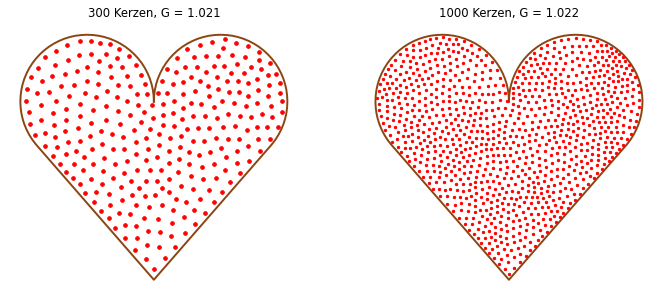

In [ ]:
import numpy as np
from matplotlib.path import Path
from scipy.spatial import cKDTree


def kuchenpunkte_np(ecken, h):
    e = np.array(ecken)
    gx, gy = np.meshgrid(np.arange(e[:, 0].min() + h / 2, e[:, 0].max(), h),
                         np.arange(e[:, 1].min() + h / 2, e[:, 1].max(), h))
    punkte = np.column_stack([gx.ravel(), gy.ravel()])
    return punkte[Path(e).contains_points(punkte)]


def lloyd_np(ecken, punkte, n, seed, max_schritte=1000):
    zufall = np.random.default_rng(seed)
    kerzen = punkte[zufall.choice(len(punkte), n, replace=False)]      # Start: n zufällige Krümel
    alt = None
    for schritt in range(max_schritte):
        abstand, zu = cKDTree(kerzen).query(punkte)                     # nächste Kerze für alle Krümel
        if alt is not None and np.array_equal(zu, alt):
            break
        alt = zu
        anzahl = np.bincount(zu, minlength=n)
        kerzen = np.column_stack([np.bincount(zu, punkte[:, 0], n) / anzahl,
                                  np.bincount(zu, punkte[:, 1], n) / anzahl])
    G = abstand.mean() / (WABE * math.sqrt(flaeche(ecken) / n))
    return kerzen, zu, schritt, G


viele = {}
for n, h in [(100, 0.25), (300, 0.25), (1000, 0.15)]:
    pkte_np = kuchenpunkte_np(herz, h)
    viele[n] = lloyd_np(herz, pkte_np, n, 1)
    print('%4d Kerzen, %5d Krümel: %3d Schritte, G = %.4f' % (n, len(pkte_np), viele[n][2], viele[n][3]))

fig, achsen = plt.subplots(1, 2, figsize=(12, 5))
for achse, n in zip(achsen, [300, 1000]):
    k = viele[n][0]
    zeichne(achse, herz, [], titel='%d Kerzen, G = %.3f' % (n, viele[n][3]))
    achse.scatter(k[:, 0], k[:, 1], color='red', s=6 if n == 1000 else 14, zorder=3)
plt.show()

Auch bei 1000 Kerzen bleibt `G` nahe 1. Wie die Lösungshinweise sagen: „Jedoch sieht man zu diesem Zeitpunkt unter den ganzen Kerzen
den Geburtstagskuchen schon nicht mehr.“ Weil der Algorithmus aufhört, sobald sich keine Krümelzuordnung mehr ändert, braucht er
bei vielen Kerzen nicht mehr Schritte als bei 100: Jedes Stück hat nur noch wenige Krümel, kleine Verschiebungen ändern nichts mehr.
Das hat eine Kehrseite: Lloyd hält dann an, bevor sich überall Waben gebildet haben, und `G` ist bei 300 und 1000 Kerzen etwas
größer als bei 100. Mit feineren Krümeln (und mehr Rechenzeit) würde es besser. Die 100 Kerzen hier (ein Zufallsstart) sind
schlechter als in Schritt 10 (1,009, Start Wabengitter): wieder ein lokales Optimum.

### Andere Kuchenformen

Unsere Funktionen funktionieren für jedes Polygon. Wir verteilen Kerzen auf das Herz der Lösungshinweise (42 Punkte der Kurve
`x = 12 sin t − 4 sin 3t`, `y = 13 cos t − 5 cos 2t − 2 cos 3t − cos 4t`, Datei `eigene_testdaten/herz_hinweise.txt`) und auf einen
fünfzackigen Stern (`eigene_testdaten/stern.txt`). Beide Dateien enthalten 0 Kerzen; die Zahl der Kerzen geben wir vor.

eigene_testdaten/herz_hinweise.txt 20 Kerzen: Fläche 561.2 cm², G = 1.020 (Start: Wabengitter)
eigene_testdaten/stern.txt          5 Kerzen: Fläche 264.6 cm², G = 1.142 (Start: Zufall 0)
eigene_testdaten/stern.txt         16 Kerzen: Fläche 264.6 cm², G = 1.067 (Start: Zufall 1)


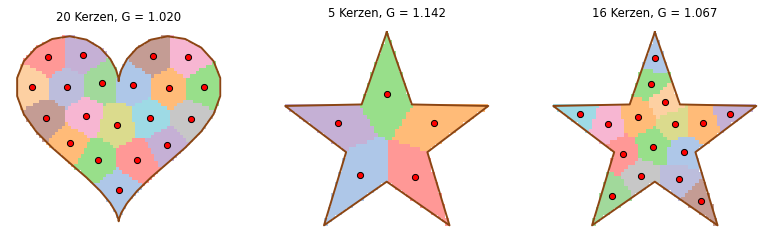

In [ ]:
fig, achsen = plt.subplots(1, 3, figsize=(14, 4.5))
formen = [('eigene_testdaten/herz_hinweise.txt', 20), ('eigene_testdaten/stern.txt', 5), ('eigene_testdaten/stern.txt', 16)]
for achse, (dateiname, n) in zip(achsen, formen):
    ecken, _ = lies_kuchen(dateiname)
    pkte = kuchenpunkte(ecken)
    e = verteile(ecken, pkte, n, zufallsstarts=2)
    print('%-34s %2d Kerzen: Fläche %.1f cm², G = %.3f (Start: %s)' % (dateiname, n, flaeche(ecken), e['G'], e['start']))
    zeichne(achse, ecken, e['kerzen'], pkte, naechste_kerze(pkte, e['kerzen'])[0], '%d Kerzen, G = %.3f' % (n, e['G']))
plt.show()

Beim Stern mit 5 Kerzen ist `G` deutlich größer als 1: Die Zacken sind schmal, ein Kuchenstück kann dort kein Sechseck sein. Das ist
keine Schwäche des Verfahrens, sondern der Form. Mit mehr Kerzen werden die Stücke kleiner als die Zacken, und `G` nähert sich
wieder 1.

### Weitere Ideen aus den Lösungshinweisen

- **Exakte Voronoi-Zerlegung:** `scipy.spatial.Voronoi(kerzen)` berechnet das Voronoi-Diagramm in der ganzen Ebene. Die Regionen
  müsste man noch mit dem Herz schneiden (das Herz ist nicht konvex, das macht es mühsam). Dann wären die Schwerpunkte exakt, und die
  Kerzen könnten sich beliebig fein bewegen.
- **Abstoßung:** Man stellt sich die Kerzen als gleich geladene Teilchen vor, die sich abstoßen, und lässt sie Schritt für Schritt
  ausweichen. Dazu braucht man eine Regel für den Rand, sonst landen alle Kerzen dort.
- **Dicke Kerzen:** Eine Erweiterung, die die Hinweise vorschlagen: Kerzen mit Gewichten, die verschieden viel Platz brauchen.

## Zum Schluss: Kerzen verteilen mit MiniZinc

MiniZinc rechnet nicht gut mit Kommazahlen, die sich frei bewegen. Wir machen aus der Aufgabe deshalb eine Auswahl: Der Kuchen wird
durch grobe Krümel im Abstand 3 cm ersetzt, und die Kerzen dürfen nur auf diesen Punkten stehen. Gesucht sind `n` Punkte, sodass die
**Summe der Wege** aller Krümel zur nächsten Kerze möglichst klein ist, also genau unser `d`, nur auf dem groben Gitter. Diese Aufgabe
heißt in der Literatur **p-Median-Problem** (Standorte für Feuerwachen oder Lager suchen).

- `kerze[j] = 1` heißt: Auf Punkt `j` steht eine Kerze, insgesamt genau `n`.
- `gehoert[i, j] = 1` heißt: Krümel `i` gehört zur Kerze auf Punkt `j`. Jeder Krümel gehört zu genau einer Kerze, und nur zu einem
  Punkt, auf dem auch eine Kerze steht.
- Minimiert wird die Summe der Abstände `d[i, j]` über alle Zuordnungen. Dass jeder Krümel wirklich zur **nächsten** Kerze gehört,
  muss man nicht verlangen: Eine weiter entfernte Kerze würde die Summe nur größer machen.

Neu gegenüber den Arbeitsblättern: Die Abstände rechnet das Modell selbst aus den Koordinaten aus. `int2float` macht aus einer ganzen
Zahl eine Kommazahl, `sqrt` zieht die Wurzel, `round` rundet wieder auf eine ganze Zahl. `"\(weg)"` setzt einen Wert in einen Text
ein, `fix(kerze[j])` ist der Wert der Variablen in der gefundenen Lösung.
```minizinc
int: P;                                   % Anzahl der Kuchenpunkte
int: n;                                   % Anzahl der Kerzen
array[1..P] of int: x;                    % Koordinaten in mm
array[1..P] of int: y;
% Abstände in mm, gerundet
array[1..P, 1..P] of int: d = array2d(1..P, 1..P,
    [round(sqrt(int2float((x[i] - x[j])^2 + (y[i] - y[j])^2))) | i, j in 1..P]);

array[1..P] of var 0..1: kerze;           % kerze[j] = 1: auf Punkt j steht eine Kerze
array[1..P, 1..P] of var 0..1: gehoert;   % gehoert[i, j] = 1: Punkt i gehört zur Kerze auf Punkt j

constraint sum(kerze) = n;
constraint forall(i in 1..P)(sum(j in 1..P)(gehoert[i, j]) = 1);
constraint forall(i, j in 1..P)(gehoert[i, j] <= kerze[j]);

var int: weg = sum(i, j in 1..P)(d[i, j] * gehoert[i, j]);
solve minimize weg;

output ["Summe der Wege: \(weg) mm\n",
        "Kerzen auf den Punkten:", concat([" \(j)" | j in 1..P where fix(kerze[j]) = 1]), "\n"];
```

Die Datendatei schreibt `als_dzn`; die Koordinaten werden in mm umgerechnet, damit es ganze Zahlen sind.

In [ ]:
def als_dzn(punkte, n):
    xs = [round(10 * p[0]) for p in punkte]
    ys = [round(10 * p[1]) for p in punkte]
    return 'P = %d;\nn = %d;\nx = %s;\ny = %s;' % (len(punkte), n, xs, ys)


grob = kuchenpunkte(herz, 3)
print(len(grob), 'grobe Krümel')
print(als_dzn(grob, 12)[:220], '...')

102 grobe Krümel
P = 102;
n = 12;
x = [-5, -35, -5, 25, -65, -35, -5, 25, 55, -65, -35, -5, 25, 55, 85, -95, -65, -35, -5, 25, 55, 85, 115, -125, -95, -65, -35, -5, 25, 55, 85, 115, -155, -125, -95, -65, -35, -5, 25, 55, 85, 115, 145, -1 ...


**Ausgabe von HiGHS für 12 Kerzen** (die Zeile `==========` heißt: optimal bewiesen):

**Ausgabe:**

```
Summe der Wege: 3319 mm
Kerzen auf den Punkten: 7 22 25 28 45 52 55 62 84 87 90 93
----------
==========
```

Die Nummern zählen ab 1, Punkt `j` ist also `grob[j - 1]`. Wir haben die Lösungen für einige Kerzenzahlen in Python übernommen und
mit unserem Maß `G` auf den feinen Krümeln bewertet:

| Kerzen | G MiniZinc (3-cm-Gitter, optimal) | G Lloyd (Schritt 10) |
|---|---|---|
| 1 | 1,046 | 1,045 |
| 2 | 1,108 | 1,100 |
| 3 | 1,022 | 1,007 |
| 5 | 1,064 | 1,050 |
| 12 | 1,043 | 1,023 |

MiniZinc findet das **beste** Ergebnis, aber nur für Kerzen auf dem groben Gitter. Lloyd kann die Kerzen frei verschieben und ist
deshalb in allen Fällen der Tabelle besser. Umgekehrt zeigt MiniZinc, dass Lloyd mit wenigen Starts nicht in einem schlechten lokalen Optimum
hängen bleibt: Auch die beste Gitterlösung ist nicht besser. Ein feineres Gitter würde helfen, aber das Modell wächst mit dem
Quadrat der Punktzahl (102 Punkte geben schon über 10.000 Variablen `gehoert`).

**Laufzeit.** Beim Erstellen dieses Notebooks haben wir gemessen:
- **HiGHS** löst 1, 2, 3, 5, 12 und 50 Kerzen auf dem 3-cm-Gitter in wenigen Sekunden; 24 Kerzen brauchten etwa 30 Sekunden. Auf
  einem 2-cm-Gitter (232 Punkte, über 50.000 Variablen) war schon bei 12 Kerzen nach 60 Sekunden noch nicht bewiesen, dass es nicht
  besser geht, und die beste gefundene Lösung war schlecht (G = 1,35).
- **Gecode** und **Chuffed** finden nach 20 Sekunden nur schlechte Lösungen (bei 3 Kerzen G = 2,97 bzw. 2,16). Sie probieren die
  Variablen der Reihe nach aus und merken spät, dass eine Kerze weit weg von vielen Krümeln steht.
- **CP-SAT** hielt bei uns das Zeitlimit nicht ein und musste beendet werden.

Wie bei vielen Zuordnungsaufgaben ist der lineare Löser HiGHS im Vorteil: Das Modell besteht nur aus Summen. Für den Kuchen bleibt
Lloyd das richtige Werkzeug: schneller, beliebig fein und für jede Kerzenzahl.